# Volet Médias · Détection précoce par l'actualité
**Master Project INGE3 n°6 · Bloc 2 « Médias et événements » · Étude de cas : crise Nexperia (sept.–nov. 2025)**

Le flux d'actualité devient un signal d'alerte en quatre étapes : collecte → déduplication → classification et entités → détection d'anomalie. On mesure ensuite l'avance obtenue sur l'impact industriel (arrêt de l'usine Honda de Celaya, Mexique, le 28/10/2025).

| Étape | Méthode | Indicateur |
|---|---|---|
| Déduplication | TF-IDF caractères + fenêtre 72 h, composantes connexes | ARI, taux de compression |
| Classification | mots-clés · TF-IDF + régression logistique · hybride | F1 macro |
| Entités | référentiel fournisseurs / lieux (alias, multilingue) | couverture |
| Signal précoce | z-score robuste (médiane / MAD glissantes) | jours d'avance |

> **Données.** Par défaut, le notebook utilise un **corpus synthétique** (préfixe `synth:`) dont les dates suivent la chronologie réelle de la crise. Les titres sont rédigés pour l'exercice : ce ne sont pas de vrais articles. Pour travailler sur des données réelles, placer l'export `collect_replay()` du notebook v2 dans `data/replay/articles_nexperia.csv` : le notebook le charge à la place du corpus synthétique, et les cellules d'évaluation, qui demandent une vérité terrain, sont alors sautées.

## 0. Configuration

In [1]:
import json, re, unicodedata
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, adjusted_rand_score, confusion_matrix, classification_report

SEED = 7
REAL_FILE = Path("data/replay/articles_nexperia.csv")
OUT = Path("data/processed"); OUT.mkdir(parents=True, exist_ok=True)
PERIOD = ("2025-09-01", "2025-11-30")
IMPACT = pd.Timestamp("2025-10-28", tz="UTC")          # arrêt Honda Celaya : événement à anticiper
SIM_THRESHOLD, WINDOW_H, MIN_CONF = 0.45, 72, 0.35
Z_ALERT, MIN_ARTICLES, MAJOR_ARTICLES, BASELINE_D = 3.0, 3, 10, 14

# Palette catégorielle validée (ordre fixe) + encre
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "figure.dpi": 110,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "xtick.color": INK2, "ytick.color": INK2,
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2})
pd.set_option("display.max_colwidth", 80)

def norm_key(s):
    s = unicodedata.normalize("NFKD", str(s))
    return re.sub(r"\s+", " ", "".join(c for c in s if not unicodedata.combining(c))).strip().lower()

def fmt_dates(ax):
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))

### 0.1 Chronologie de référence (faits publics)

In [2]:
MILESTONES = pd.DataFrame([
    ("M1", "2025-09-29", "sanction", "États-Unis : règle « Affiliates » de la BIS, Nexperia couverte via Wingtech"),
    ("M2", "2025-10-04", "sanction", "Chine : interdiction d'exporter les produits de Nexperia Chine"),
    ("M3", "2025-10-12", "sanction", "Pays-Bas : prise de contrôle (loi de 1952) rendue publique"),
    ("M4", "2025-10-16", "penurie",  "Constructeurs européens : alerte sur une pénurie imminente"),
    ("M5", "2025-10-22", "penurie",  "Volkswagen prévient d'un arrêt de production possible"),
    ("M6", "2025-10-28", "penurie",  "Honda arrête son usine de Celaya (Mexique)"),
    ("M7", "2025-11-09", "sanction", "Chine : exemptions à l'interdiction d'exporter"),
    ("M8", "2025-11-19", "sanction", "Pays-Bas : suspension de l'ordonnance"),
], columns=["id", "date", "type", "jalon"])
MILESTONES["date"] = pd.to_datetime(MILESTONES["date"], utc=True)
MILESTONES.assign(date=MILESTONES["date"].dt.date)

,id,date,type,jalon
0,M1,2025-09-29,sanction,"États-Unis : règle « Affiliates » de la BIS, Nexperia couverte via Wingtech"
1,M2,2025-10-04,sanction,Chine : interdiction d'exporter les produits de Nexperia Chine
2,M3,2025-10-12,sanction,Pays-Bas : prise de contrôle (loi de 1952) rendue publique
3,M4,2025-10-16,penurie,Constructeurs européens : alerte sur une pénurie imminente
4,M5,2025-10-22,penurie,Volkswagen prévient d'un arrêt de production possible
5,M6,2025-10-28,penurie,Honda arrête son usine de Celaya (Mexique)
6,M7,2025-11-09,sanction,Chine : exemptions à l'interdiction d'exporter
7,M8,2025-11-19,sanction,Pays-Bas : suspension de l'ordonnance


## 1. Corpus

### 1.1 Référentiels

In [3]:
COMPANIES = {  # id : (nom, alias, rang dans la chaîne)
    "S001": ("Nexperia", ["Nexperia B.V.", "Nexperia China"], 3), "S002": ("Wingtech", ["Wingtech Technology"], 3),
    "S003": ("Bosch", ["Robert Bosch"], 1), "S004": ("ZF", ["ZF Friedrichshafen"], 1), "S005": ("Continental", [], 1),
    "S006": ("Valeo", [], 1), "C001": ("Honda", ["Honda Motor"], 0), "C002": ("Volkswagen", ["VW"], 0),
    "C003": ("Nissan", [], 0), "C004": ("Stellantis", [], 0),
}
PLACES = {  # nom : (alias, lat, lon, pays, précision 3=site/port 2=ville 1=pays)
    "Nijmegen": (["Nimègue"], 51.842, 5.853, "NL", 2), "Hamburg": (["Hambourg", "Hamburger"], 53.551, 9.994, "DE", 2),
    "Dongguan": ([], 23.021, 113.752, "CN", 2), "Beijing": (["Pékin"], 39.904, 116.407, "CN", 2),
    "The Hague": (["La Haye", "Den Haag"], 52.070, 4.300, "NL", 2), "Wolfsburg": ([], 52.423, 10.787, "DE", 2),
    "Celaya": ([], 20.523, -100.815, "MX", 2), "Port of Antwerp": (["port d'Anvers", "Antwerp"], 51.270, 4.340, "BE", 3),
    "Port of Le Havre": (["port du Havre", "Le Havre"], 49.480, 0.130, "FR", 3), "Port of Rotterdam": (["Rotterdam"], 51.948, 4.142, "NL", 3),
    "Rhine": (["Rhin", "Rhein"], 50.0, 7.6, "DE", 2), "Lyon": ([], 45.764, 4.836, "FR", 2), "Taiwan": (["Taïwan"], 23.70, 120.96, "TW", 1),
    "Netherlands": (["Pays-Bas", "Niederlande", "Dutch", "Nederlandse"], 52.13, 5.29, "NL", 1),
    "China": (["Chine", "Chinese", "Beijing's"], 35.86, 104.20, "CN", 1), "Mexico": (["Mexique", "mexicaine"], 23.63, -102.55, "MX", 1),
    "Germany": (["Allemagne", "German"], 51.17, 10.45, "DE", 1), "Europe": (["européens", "European", "Europäische"], 50.0, 10.0, "EU", 1),
}
def _alias_index(d, names):
    return {norm_key(a): k for k, v in d.items() for a in [names(k, v), *v[1 if d is COMPANIES else 0]]}
CO_INDEX = _alias_index(COMPANIES, lambda k, v: v[0])
PL_INDEX = _alias_index(PLACES, lambda k, v: k)
print(f"{len(COMPANIES)} entreprises · {len(PLACES)} lieux · {len(CO_INDEX) + len(PL_INDEX)} alias")

10 entreprises · 18 lieux · 62 alias


### 1.2 Chargement

In [4]:
rng = np.random.default_rng(SEED)
def pick(t):  # « [a|b|c] » → une des variantes
    return re.sub(r"\[([^\]]+)\]", lambda m: rng.choice(m.group(1).split("|")), t)

# Gabarits par jalon : (langue, titre, texte). Les variantes [a|b] simulent la reprise d'une dépêche par plusieurs médias.
T = {
 "M1": [("en", "US [extends|widens] Entity List to affiliates, Nexperia [caught|hit] by new export control rule",
         "The affiliates rule covers subsidiaries at least 50% owned by listed firms such as Wingtech, parent of Nijmegen-based Nexperia."),
        ("en", "Washington's 50% rule puts Wingtech unit Nexperia under export restrictions", "Chipmaker Nexperia, based in Nijmegen, falls under the entity list."),
        ("fr", "Contrôle des exportations : Nexperia [visée|concernée] par la nouvelle règle américaine", "Filiale de Wingtech, le fabricant de puces de Nimègue entre dans le champ de l'entity list.")],
 "M2": [("en", "China [bans|blocks] exports of Nexperia chips made in Dongguan", "Beijing's commerce ministry imposed an export ban on Nexperia China and its subcontractors."),
        ("en", "Beijing [imposes|announces] export restriction on Nexperia's Chinese unit", "The export ban targets finished chips assembled in Dongguan, China."),
        ("fr", "Chine : interdiction d'exportation pour les puces Nexperia assemblées à Dongguan", "Pékin interdit l'export des produits finis de Nexperia China."),
        ("de", "China verhängt Exportverbot für Nexperia-Chips aus Dongguan", "Das Exportverbot trifft Zulieferer in Europa.")],
 "M3": [("en", "Dutch government [takes control of|seizes control of] chipmaker Nexperia under Cold War-era law",
         "The Hague invoked the Goods Availability Act and a court suspended the chief executive of Wingtech-owned Nexperia."),
        ("en", "Netherlands [seizes|takes over] Chinese-owned Nexperia citing supply risks", "The Dutch move in The Hague follows US export controls on Wingtech."),
        ("fr", "Les Pays-Bas [prennent le contrôle de|placent sous tutelle] Nexperia", "La Haye invoque une loi de 1952 contre le fabricant de puces de Nimègue, propriété de Wingtech."),
        ("de", "Niederlande übernehmen Kontrolle über Chiphersteller Nexperia", "Den Haag greift beim Wingtech-Konzern ein."),
        ("nl", "Nederlandse overheid grijpt in bij chipmaker Nexperia", "Het kabinet in Den Haag gebruikt de Wet beschikbaarheid goederen.")],
 "M4": [("en", "European carmakers warn of [chip shortage|supply disruption] as Nexperia supplies dry up",
         "Bosch and ZF fear production halts in Europe within weeks."),
        ("en", "Automakers' lobby warns of production halts over Nexperia standoff", "Stocks of Nexperia chips are running low across Europe."),
        ("fr", "Pénurie de puces Nexperia : les constructeurs européens [s'inquiètent|tirent la sonnette d'alarme]", "Valeo et Bosch redoutent des arrêts de production en Europe."),
        ("de", "Zulieferer warnen vor Lieferengpass bei Nexperia-Chips", "Bosch und ZF in Deutschland prüfen Kurzarbeit.")],
 "M5": [("en", "Volkswagen [warns of|prepares for] production stoppage as Nexperia chip shortage bites", "Output at Wolfsburg could halt as Nexperia chips run out."),
        ("en", "VW [flags|braces for] production halt at Wolfsburg over missing Nexperia chips", "Volkswagen told workers a stoppage could be imminent in Germany."),
        ("fr", "Volkswagen redoute un arrêt de production faute de puces Nexperia", "Le site de Wolfsburg pourrait s'arrêter."),
        ("de", "VW droht Produktionsstopp wegen Nexperia-Lieferengpass", "In Wolfsburg könnten die Bänder stillstehen.")],
 "M6": [("en", "Honda [halts|suspends] production at Celaya plant in Mexico over chip shortage", "The Nexperia chip shortage forced Honda to stop its Mexico line."),
        ("en", "Nexperia chip shortage forces Honda to [suspend|cut] output in Mexico", "Honda halts production at Celaya; North American plants cut output."),
        ("fr", "Honda suspend la production de son usine mexicaine faute de puces", "Pénurie de puces Nexperia : arrêt de production à Celaya, Mexique.")],
 "M7": [("en", "China [grants|approves] exemptions to Nexperia export ban", "Beijing eases the export restriction on chips from Dongguan for civilian use."),
        ("fr", "La Chine assouplit l'interdiction d'exportation des puces Nexperia", "Pékin accorde des exemptions pour Nexperia China.")],
 "M8": [("en", "Netherlands suspends Nexperia [order|takeover] as gesture of goodwill", "The Hague suspends its control order over Wingtech-owned Nexperia."),
        ("fr", "Les Pays-Bas suspendent leur décret sur Nexperia", "La Haye fait un geste envers Pékin dans le dossier Nexperia.")],
}
INTENSITY = {"M1": 3, "M2": 4, "M3": 26, "M4": 12, "M5": 14, "M6": 16, "M7": 9, "M8": 8}   # articles attendus le jour J
TAU = 2.2                                                                                       # décroissance (jours)

BG = {  # bruit de fond : autres événements supply chain + faux positifs (aucun)
 "greve": [("en", "Dockworkers [strike|walk out] at the Port of [Antwerp|Rotterdam], [container traffic|cargo handling] halted", "The strike blocks terminals."),
           ("fr", "Grève au port du Havre : les terminaux à l'arrêt", "Les dockers du Havre cessent le travail."),
           ("de", "Streik im Hamburger Hafen legt Containerumschlag lahm", "Hafenarbeiter in Hamburg streiken.")],
 "catastrophe": [("en", "[Floods|Heavy flooding|Storms] force [factory|plant] closures [along the Rhine|in Germany|in Taiwan]", "Several plants suspend operations."),
                 ("en", "Typhoon shuts chip plants in Taiwan", "Fabs in Taiwan suspend operations as the typhoon makes landfall."),
                 ("fr", "Incendie dans une usine de composants près de Lyon", "L'incendie a détruit l'entrepôt du fournisseur.")],
 "faillite": [("en", "[Auto parts|Seat|Wiring|Tyre] supplier [files for insolvency|enters insolvency proceedings]", "The supplier blames falling orders."),
              ("fr", "Un équipementier automobile placé en redressement judiciaire", "Le fournisseur de Valeo et Stellantis cherche un repreneur."),
              ("de", "Zulieferer meldet Insolvenz an", "Der Autozulieferer aus Deutschland ist zahlungsunfähig.")],
 "cyberattaque": [("en", "Ransomware attack forces carmaker to shut production lines", "IT systems were taken offline after the cyberattack."),
                  ("fr", "Une cyberattaque paralyse un sous-traitant automobile", "Le rançongiciel a bloqué les serveurs de l'usine.")],
 "logistique": [("en", "Low water on the Rhine restricts barge traffic to Germany", "Shipping costs rise as vessels load less cargo."),
                ("en", "Port congestion in Rotterdam delays container ships", "Vessels wait for days at the Port of Rotterdam.")],
 "penurie": [("en", "Rare earth magnet shortage idles Nissan plant", "Nissan halts a line for a week as magnets run low.")],
 "aucun_nex": [("en", "Nexperia [launches|unveils] new [automotive MOSFET range|GaN power devices|ESD protection diodes]", "The Nijmegen chipmaker expands its portfolio.")],
 "aucun": [("en", "Bosch opens new research centre and hires engineers", "The supplier invests in Germany."),
           ("fr", "Stellantis présente son nouveau SUV électrique", "Le constructeur dévoile son modèle au salon."),
           ("en", "Port of Rotterdam reports record quarterly volumes", "Container throughput rose in Rotterdam.")],
}
BG_RATE = {"greve": .9, "catastrophe": .7, "faillite": .7, "cyberattaque": .4, "logistique": .6, "penurie": .3, "aucun": 1.2, "aucun_nex": .1}

def synth_corpus():
    rows, days = [], pd.date_range(*PERIOD, tz="UTC")
    def emit(day, lang, title, text, etype, true_evt, tmpl):
        ts = day + pd.Timedelta(minutes=int(rng.integers(6 * 60, 22 * 60)))
        rows.append(dict(published_at=ts, language=lang, title=pick(title), text=text, true_type=etype, true_event=true_evt, template=tmpl))
    for _, m in MILESTONES.iterrows():
        for d in range(0, 12):
            for _ in range(rng.poisson(INTENSITY[m.id] * np.exp(-d / TAU))):
                k = int(rng.integers(len(T[m.id]))); lang, ti, tx = T[m.id][k]
                emit(m.date + pd.Timedelta(days=d), lang, ti, tx, m.type, m.id, f"{m.id}-{k}")
    n_bg = 0
    for day in days:
        for etype, lam in BG_RATE.items():
            for _ in range(rng.poisson(lam)):
                n_bg += 1; k = int(rng.integers(len(BG[etype]))); lang, ti, tx = BG[etype][k]
                for j in range(1 + rng.poisson(1.2)):            # reprises sur 0 à 2 jours
                    emit(day + pd.Timedelta(days=int(rng.integers(0, 3))), lang, ti, tx, etype.replace("_nex", ""), f"B{n_bg:04d}", f"{etype}-{k}")
    df = pd.DataFrame(rows)
    df = df[df["published_at"] < pd.Timestamp(PERIOD[1], tz="UTC") + pd.Timedelta(days=1)]
    df = df.sort_values("published_at").reset_index(drop=True)
    df.insert(0, "source_id", [f"synth:{i:05d}" for i in range(len(df))])
    return df

if REAL_FILE.exists():
    corpus = pd.read_csv(REAL_FILE, parse_dates=["published_at"]); SYNTH = False
    corpus["text"] = corpus.get("text", "").fillna("")
else:
    corpus = synth_corpus(); SYNTH = True
corpus["content"] = corpus["title"] + ". " + corpus["text"].fillna("")
print(f"Source : {'corpus synthétique (vérité terrain disponible)' if SYNTH else REAL_FILE}")
print(f"{len(corpus):,} articles · {corpus.published_at.min():%d/%m/%Y} → {corpus.published_at.max():%d/%m/%Y}".replace(",", " "))
corpus[["source_id", "published_at", "language", "title"]].sample(6, random_state=1).sort_values("published_at")

Source : corpus synthétique (vérité terrain disponible)
1 225 articles · 01/09/2025 → 30/11/2025


,source_id,published_at,language,title
159,synth:00159,2025-09-18 14:47:00+00:00,en,"Dockworkers walk out at the Port of Rotterdam, container traffic halted"
341,synth:00341,2025-10-04 10:54:00+00:00,en,"Dockworkers walk out at the Port of Antwerp, container traffic halted"
686,synth:00686,2025-10-20 09:04:00+00:00,de,Zulieferer meldet Insolvenz an
763,synth:00763,2025-10-24 09:02:00+00:00,de,VW droht Produktionsstopp wegen Nexperia-Lieferengpass
915,synth:00915,2025-11-03 13:57:00+00:00,en,Rare earth magnet shortage idles Nissan plant
1149,synth:01149,2025-11-21 10:58:00+00:00,fr,Grève au port du Havre : les terminaux à l'arrêt


### 1.3 Vue d'ensemble

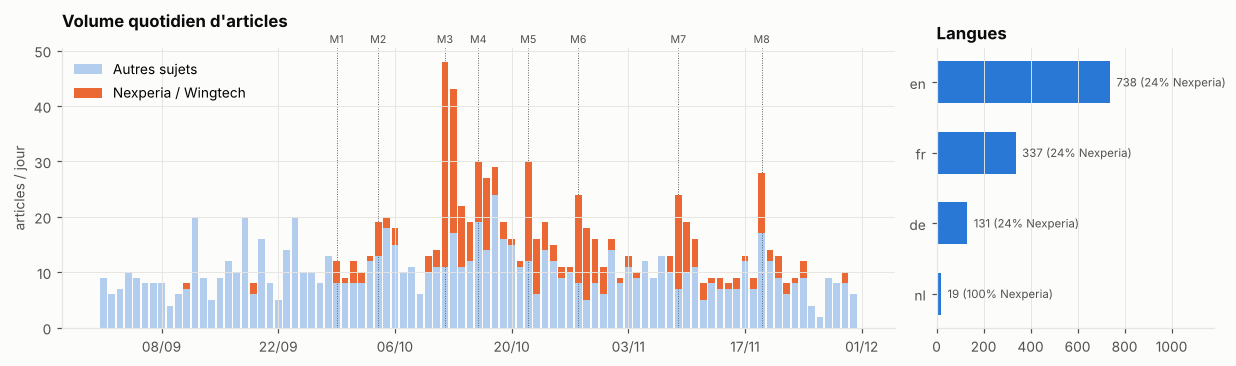

Nexperia : 305 articles (25%) · 4 langues


In [5]:
NEX = re.compile(r"nexperia|wingtech", re.I)
corpus["nexperia"] = corpus["content"].str.contains(NEX)
daily = (corpus.set_index("published_at").groupby([pd.Grouper(freq="D"), "nexperia"]).size()
         .unstack(fill_value=0).reindex(columns=[False, True], fill_value=0))
daily.columns = ["Autres sujets", "Nexperia / Wingtech"]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.4), gridspec_kw={"width_ratios": [3, 1]})
ax.bar(daily.index, daily.iloc[:, 0], width=.8, color=C[0], alpha=.35, label=daily.columns[0])
ax.bar(daily.index, daily.iloc[:, 1], width=.8, bottom=daily.iloc[:, 0], color=C[1], label=daily.columns[1])
for _, m in MILESTONES.iterrows():
    ax.axvline(m.date, color=INK2, lw=.6, ls=":", zorder=0)
    ax.text(m.date, 1.01, m.id, ha="center", va="bottom", fontsize=7, color=INK2, transform=ax.get_xaxis_transform())
ax.set_title("Volume quotidien d'articles", pad=14); ax.set_ylabel("articles / jour"); fmt_dates(ax); ax.legend(loc="upper left")
lang = corpus.groupby("language")["nexperia"].agg(["size", "mean"]).sort_values("size")
ax2.barh(lang.index, lang["size"], color=C[0], height=.6)
for y, (n, p) in enumerate(lang.values): ax2.text(n, y, f"  {int(n)} ({p:.0%} Nexperia)", va="center", fontsize=7.5, color=INK2)
ax2.set_title("Langues"); ax2.set_xlim(0, lang["size"].max() * 1.6); ax2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Nexperia : {corpus.nexperia.sum()} articles ({corpus.nexperia.mean():.0%}) · {corpus.loc[corpus.nexperia, 'language'].nunique()} langues")

**Lecture.** Avant le 29/09, Nexperia n'apparaît que dans de rares annonces de produits. Les deux premiers jalons (M1, M2) produisent un signal faible, quelques articles par jour, puis l'annonce néerlandaise du 12/10 (M3) fait exploser le volume. Le sujet occupe ensuite le flux par vagues successives, une par jalon. **40 % du corpus n'est pas en anglais**, et toute la couverture en néerlandais concerne Nexperia : la presse locale du fournisseur compte.

## 2. Déduplication : des articles aux événements

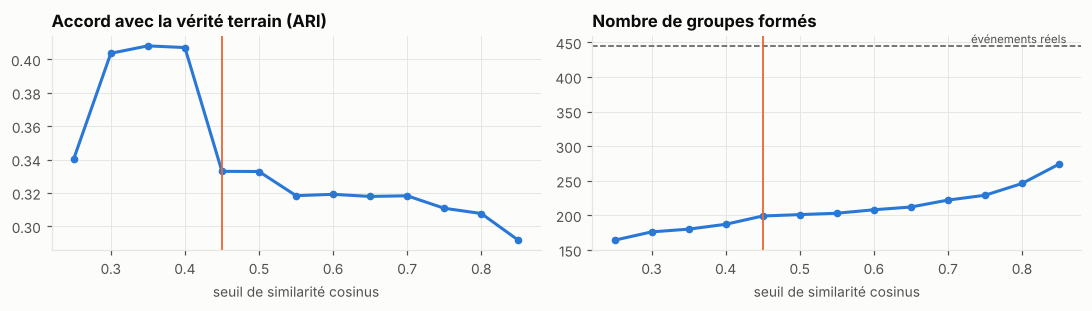

1225 articles → 199 groupes (compression ×6.2) · ARI = 0.333 au seuil 0.45 · optimum 0.408 à 0.35


,articles,debut,titre
cluster_id,,,
evt_0129,23,2025-10-28 07:48:00+00:00,Nexperia chip shortage forces Honda to cut output in Mexico
evt_0130,21,2025-10-28 09:19:00+00:00,Honda suspend la production de son usine mexicaine faute de puces
evt_0086,19,2025-10-12 06:13:00+00:00,Nederlandse overheid grijpt in bij chipmaker Nexperia
evt_0157,17,2025-11-09 06:33:00+00:00,La Chine assouplit l'interdiction d'exportation des puces Nexperia
evt_0158,16,2025-11-09 07:47:00+00:00,China grants exemptions to Nexperia export ban
evt_0085,16,2025-10-12 06:04:00+00:00,Netherlands takes over Chinese-owned Nexperia citing supply risks


In [6]:
def deduplicate(df, threshold=SIM_THRESHOLD, window_h=WINDOW_H, X=None):
    df = df.sort_values("published_at").reset_index(drop=True)
    if X is None:
        X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit_transform(df["title"].map(norm_key))
    S, ts, n = cosine_similarity(X, dense_output=False), df["published_at"].values, len(df)
    parent = np.arange(n)
    def find(i):
        while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
        return i
    S = S.tocoo()
    for i, j, s in zip(S.row, S.col, S.data):
        if i < j and s >= threshold and abs(ts[j] - ts[i]) <= np.timedelta64(window_h, "h"):
            parent[find(j)] = find(i)
    roots = np.array([find(i) for i in range(n)])
    order = {r: k for k, r in enumerate(dict.fromkeys(roots), 1)}
    df["cluster_id"] = [f"evt_{order[r]:04d}" for r in roots]
    df["cluster_size"] = df.groupby("cluster_id")["source_id"].transform("size")
    return df

corpus = corpus.sort_values("published_at").reset_index(drop=True)
X_titles = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit_transform(corpus["title"].map(norm_key))
if SYNTH:
    sweep = []
    for th in np.arange(.25, .86, .05):
        d = deduplicate(corpus, th, X=X_titles)
        sweep.append((round(th, 2), adjusted_rand_score(d["true_event"], d["cluster_id"]), d["cluster_id"].nunique()))
    sweep = pd.DataFrame(sweep, columns=["seuil", "ARI", "clusters"])
    best = sweep.loc[sweep["ARI"].idxmax()]
    fig, axs = plt.subplots(1, 2, figsize=(10, 2.9))
    axs[0].plot(sweep["seuil"], sweep["ARI"], color=C[0], marker="o", ms=4)
    axs[1].plot(sweep["seuil"], sweep["clusters"], color=C[0], marker="o", ms=4)
    axs[1].axhline(corpus["true_event"].nunique(), color=INK2, ls="--", lw=1)
    axs[1].text(.86, corpus["true_event"].nunique(), " événements réels", va="bottom", ha="right", fontsize=7.5, color=INK2)
    for a, t in zip(axs, ["Accord avec la vérité terrain (ARI)", "Nombre de groupes formés"]):
        a.axvline(SIM_THRESHOLD, color=C[1], lw=1.2); a.set_title(t); a.set_xlabel("seuil de similarité cosinus")
    plt.tight_layout(); plt.show()

corpus = deduplicate(corpus, X=X_titles)
n_evt = corpus["cluster_id"].nunique()
print(f"{len(corpus)} articles → {n_evt} groupes (compression ×{len(corpus) / n_evt:.1f})"
      + (f" · ARI = {adjusted_rand_score(corpus['true_event'], corpus['cluster_id']):.3f} au seuil {SIM_THRESHOLD}"
         f" · optimum {best['ARI']:.3f} à {best['seuil']}" if SYNTH else ""))
corpus[corpus.nexperia].groupby("cluster_id").agg(articles=("source_id", "size"), debut=("published_at", "min"),
    titre=("title", "first")).sort_values("articles", ascending=False).head(6)

**Lecture.** L'accord reste modéré (ARI ≈ 0,33 au seuil 0,45, optimum ≈ 0,41 vers 0,35), à cause de deux erreurs de sens opposé :
- **fusion** : deux événements distincts mais titrés à l'identique à moins de 72 h (deux grèves successives au même port) sont regroupés. Il y a moins de groupes formés que d'événements réels ;
- **éclatement** : un même jalon couvert en plusieurs langues donne plusieurs groupes, car le TF-IDF sur caractères ne rapproche pas « Pays-Bas » de « Netherlands ».

Les titres seuls ne suffisent pas : il faut le texte, des embeddings multilingues (`USE_EMBEDDINGS` dans le notebook v2) et un seuil calibré sur des paires réelles annotées. Le seuil de 0,45 est conservé tant que cette calibration n'est pas faite.

## 3. Classification des événements

In [7]:
KW = {
 "greve": ["strike", "walk out", "walkout", "grève", "streik", "staking"],
 "catastrophe": ["flood", "typhoon", "earthquake", "fire", "incendie", "inondation", "séisme", "hochwasser"],
 "sanction": ["export ban", "export control", "export restriction", "entity list", "sanction", "embargo", "takes control",
              "seizes", "interdiction d'exportation", "contrôle des exportations", "exportverbot", "sous tutelle"],
 "faillite": ["insolvency", "bankruptcy", "receivership", "redressement judiciaire", "liquidation", "insolvenz"],
 "cyberattaque": ["ransomware", "cyberattack", "cyberattaque", "rançongiciel", "cyberangriff"],
 "penurie": ["shortage", "production halt", "halts production", "stoppage", "pénurie", "arrêt de production",
             "lieferengpass", "produktionsstopp"],
 "logistique": ["port congestion", "barge", "low water", "container ships", "port closure", "fermeture du port"],
}
def kw_classify(text):
    t = norm_key(text)
    hits = {c: sum(bool(re.search(rf"(?<!\w){re.escape(norm_key(k))}", t)) for k in ks) for c, ks in KW.items()}
    best = max(hits, key=hits.get)
    return best if hits[best] else "aucun"

# Jeu d'amorçage du notebook v2 : 64 phrases écrites à la main, sans lien avec Nexperia (aucune fuite de la réponse)
SEED_EXAMPLES = {
 "greve": ["Dockworkers begin an indefinite strike at the container terminal", "Union calls a 48-hour walkout at the car assembly plant",
           "Rail freight drivers vote for industrial action over pay", "Les salariés de l'usine votent la grève illimitée",
           "Débrayage massif chez l'équipementier automobile après l'échec des négociations", "Streik legt das Werk des Zulieferers lahm",
           "Port workers walk off the job, halting cargo handling", "Truck drivers strike blocks deliveries to factories"],
 "catastrophe": ["Magnitude 7 earthquake forces chip fabs to evacuate", "Severe floods submerge industrial park and close factories",
                 "Typhoon makes landfall, plants suspend operations", "Huge fire destroys warehouse of electronics supplier",
                 "Un séisme endommage plusieurs usines de composants", "Inondations : la zone industrielle sous les eaux, production à l'arrêt",
                 "Hurricane shuts down quartz mines and nearby plants", "Explosion at chemical plant kills workers and halts output"],
 "sanction": ["Washington adds chipmaker to trade blacklist, restricting exports", "New export controls target advanced semiconductor equipment",
              "EU imposes sanctions on metals producer", "Government bans exports of rare earth magnets without licence",
              "Pékin impose des restrictions à l'exportation de terres rares", "Le gouvernement place l'entreprise sous tutelle au nom de la sécurité nationale",
              "Embargo on steel imports comes into force", "Company added to the Entity List over national security concerns"],
 "faillite": ["Auto parts supplier files for bankruptcy protection", "Battery maker enters insolvency proceedings after funding collapse",
              "Seat manufacturer placed in receivership", "L'équipementier est placé en redressement judiciaire",
              "Liquidation judiciaire prononcée pour le fabricant de pièces", "Zulieferer meldet Insolvenz an",
              "Supplier files for Chapter 11 amid falling orders", "Creditors push tyre maker into administration"],
 "cyberattaque": ["Ransomware attack forces carmaker to shut down IT systems", "Hackers breach supplier network, production systems offline",
                  "Cyberattack halts operations at logistics group", "Une cyberattaque paralyse les usines du constructeur",
                  "Rançongiciel : l'équipementier coupe ses serveurs", "Cyberangriff legt Produktion beim Autobauer lahm",
                  "Data breach at parts maker exposes customer files", "Factory lines stopped after malware infects control systems"],
 "penurie": ["Chip shortage forces automaker to cut output at two plants", "Carmaker halts production line because of missing components",
             "Supplier warns it cannot guarantee deliveries of parts", "Pénurie de composants : l'usine réduit sa production de moitié",
             "Arrêt de production d'une semaine faute de pièces", "Lieferengpass bei Halbleitern stoppt die Bänder",
             "Magnet shortage idles SUV assembly plant for a week", "Automakers warn of supply disruption as stocks run low"],
 "logistique": ["Container ship runs aground and blocks canal traffic", "Port congestion delays cargo for weeks",
                "Port closed to vessels after bridge collapse", "Shipping lines reroute vessels around the cape, adding two weeks",
                "Fermeture du port : les navires déroutés", "Low water on the Rhine restricts barge traffic",
                "Rail line closure cuts freight link to the terminal", "Border delays leave trucks queuing for days"],
 "aucun": ["City council approves new bike lanes downtown", "Football club wins the national championship",
           "Carmaker unveils new electric SUV at motor show", "Le groupe annonce de bons résultats trimestriels",
           "Company appoints new chief financial officer", "Museum opens exhibition on modern art",
           "Supplier opens new research centre and hires engineers", "Shares rise after strong quarterly earnings"],
}
seed = pd.DataFrame([(t, l) for l, ts in SEED_EXAMPLES.items() for t in ts], columns=["text", "label"])
lr = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, preprocessor=norm_key),
                   LogisticRegression(C=10, max_iter=2000, class_weight="balanced")).fit(seed["text"], seed["label"])

proba = lr.predict_proba(corpus["content"])
corpus["kw_type"] = corpus["content"].map(kw_classify)
corpus["lr_type"], corpus["lr_conf"] = lr.classes_[proba.argmax(1)], proba.max(1)
# Règle retenue : la règle explicite d'abord, le modèle appris en repli, « aucun » si personne n'est confiant
has_kw, conf_lr = corpus["kw_type"] != "aucun", corpus["lr_conf"] >= MIN_CONF
corpus["event_type"] = np.where(has_kw, corpus["kw_type"], np.where(conf_lr, corpus["lr_type"], "aucun"))
corpus["type_method"] = np.where(has_kw, "mots-cles", np.where(conf_lr, "tfidf_lr", "defaut"))
print("Décision :", corpus["type_method"].value_counts(normalize=True).round(2).to_dict())

Décision : {'mots-cles': 0.72, 'defaut': 0.19, 'tfidf_lr': 0.09}


,F1 macro,exactitude,F1 macro · Nexperia
Mots-clés,0.949,0.938,0.767
TF-IDF + LR,0.848,0.830,0.721
Hybride (retenu),0.957,0.949,0.767


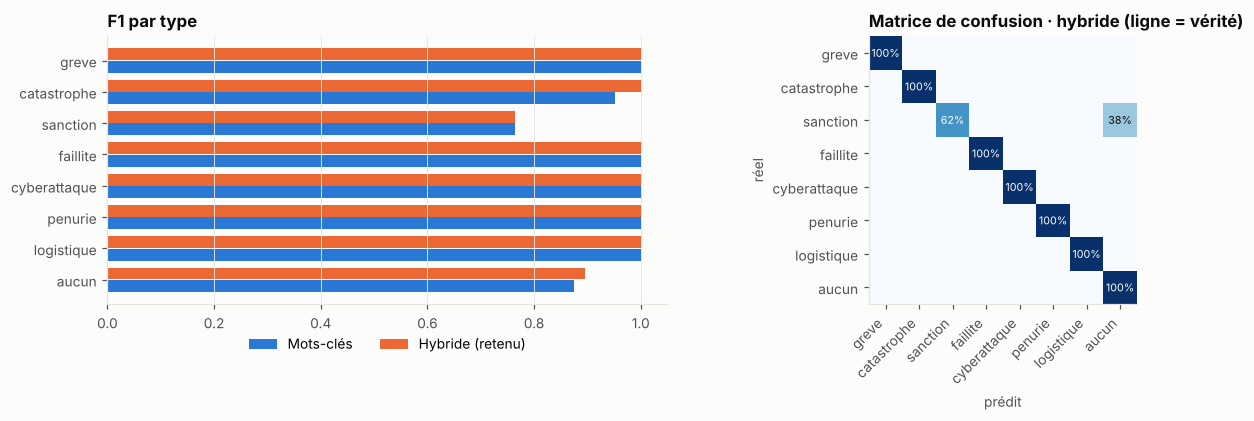

In [8]:
if SYNTH:
    LABELS = list(KW) + ["aucun"]
    scores = pd.DataFrame({name: [f1_score(corpus["true_type"], corpus[col], average="macro", labels=LABELS),
                                  (corpus["true_type"] == corpus[col]).mean(),
                                  f1_score(corpus.loc[corpus.nexperia, "true_type"], corpus.loc[corpus.nexperia, col], average="macro",
                                           labels=sorted(corpus.loc[corpus.nexperia, "true_type"].unique()))]
                           for name, col in [("Mots-clés", "kw_type"), ("TF-IDF + LR", "lr_type"), ("Hybride (retenu)", "event_type")]},
                          index=["F1 macro", "exactitude", "F1 macro · Nexperia"]).T.round(3)
    display(scores)

    per_cls = pd.DataFrame({n: f1_score(corpus["true_type"], corpus[c], average=None, labels=LABELS)
                            for n, c in [("Mots-clés", "kw_type"), ("Hybride (retenu)", "event_type")]}, index=LABELS)
    cm = confusion_matrix(corpus["true_type"], corpus["event_type"], labels=LABELS, normalize="true")
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
    y = np.arange(len(LABELS))
    a1.barh(y + .2, per_cls.iloc[:, 0], .38, color=C[0], label=per_cls.columns[0])
    a1.barh(y - .2, per_cls.iloc[:, 1], .38, color=C[1], label=per_cls.columns[1])
    a1.set_yticks(y, LABELS); a1.invert_yaxis(); a1.set_xlim(0, 1.05); a1.set_title("F1 par type"); a1.legend(loc="upper center", bbox_to_anchor=(.5, -.07), ncol=2)
    a1.grid(axis="y", visible=False)
    im = a2.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a2.set_xticks(y, LABELS, rotation=45, ha="right"); a2.set_yticks(y, LABELS); a2.grid(False)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if cm[i, j] >= .05: a2.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > .55 else INK)
    a2.set_title("Matrice de confusion · hybride (ligne = vérité)"); a2.set_xlabel("prédit"); a2.set_ylabel("réel")
    plt.tight_layout(); plt.show()

**Lecture.** Sur l'ensemble du corpus, l'hybride (mots-clés d'abord, régression logistique en repli) obtient un F1 macro de 0,96. La régression seule plafonne à 0,85 : 64 phrases d'amorçage ne suffisent pas pour généraliser. Ce score est **optimiste**, car le vocabulaire des gabarits synthétiques recoupe celui des listes de mots-clés.

Le chiffre utile est celui du **sous-corpus Nexperia (0,77)**. 38 % des articles « sanction » y sont manqués, pour deux raisons :
- **multilinguisme** : les variantes française, allemande et néerlandaise de la prise de contrôle (« prennent le contrôle », « übernehmen Kontrolle », « grijpt in ») ne déclenchent aucune règle. Le jalon le plus important (M3) perd ainsi une partie de sa couverture ;
- **désescalade** : la suspension de l'ordonnance (M8) est entièrement classée « aucun ». L'outil voit l'escalade mais pas sa fin.

Le zero-shot NLI multilingue (option `USE_ZERO_SHOT` du v2) et un champ `polarite` répondent à ces deux défauts.

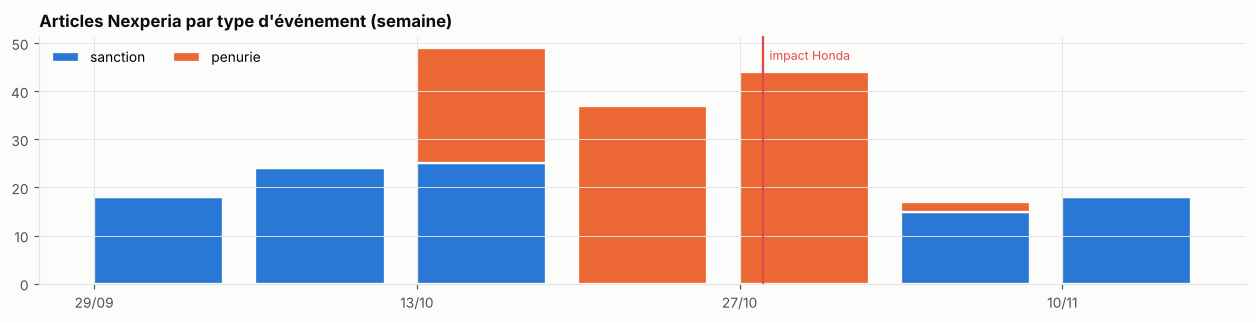

In [9]:
nx_week = (corpus[corpus.nexperia & (corpus.event_type != "aucun")].set_index("published_at")
           .groupby([pd.Grouper(freq="W-MON", label="left", closed="left"), "event_type"]).size().unstack(fill_value=0))
order = [c for c in ["sanction", "penurie", "logistique", "greve", "catastrophe", "faillite", "cyberattaque"] if c in nx_week]
fig, ax = plt.subplots(figsize=(11.5, 3))
bottom = np.zeros(len(nx_week))
for k, c in enumerate(order):
    ax.bar(nx_week.index, nx_week[c], width=5.6, bottom=bottom, color=C[k], label=c, edgecolor=SURF, linewidth=1.5, align="edge")
    bottom += nx_week[c].values
ax.axvline(IMPACT, color=C[7], lw=1.5); ax.text(IMPACT, bottom.max(), "  impact Honda", color=C[7], fontsize=8, va="top")
ax.set_title("Articles Nexperia par type d'événement (semaine)"); ax.legend(ncol=len(order), loc="upper left"); fmt_dates(ax)
plt.tight_layout(); plt.show()

**Lecture.** La crise change de nature. Jusqu'au 12/10, elle est **réglementaire** (« sanction »). À partir du 16/10, elle devient **industrielle** (« pénurie »). Ce basculement de type sur une même entité précède de 12 jours l'arrêt de l'usine Honda. C'est un marqueur qualitatif à transmettre au moteur de risque, en plus du volume. Après le 3/11, le retour à « sanction » correspond à la levée des restrictions (M7) : sans polarité, on ne peut pas le distinguer de l'escalade.

## 4. Entités et liens

2071 mentions tracées (source_id) · articles avec ≥1 entreprise : 43% · avec ≥1 lieu : 79%


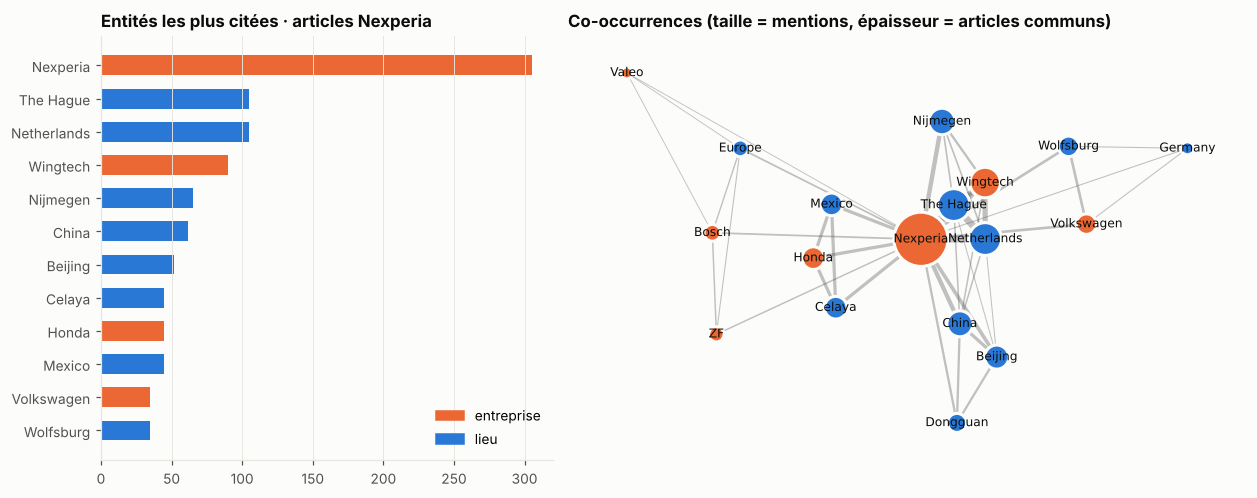

In [10]:
CO_RX = [(re.compile(rf"(?<!\w){re.escape(a)}(?!\w)"), k) for a, k in sorted(CO_INDEX.items(), key=lambda x: -len(x[0]))]
PL_RX = [(re.compile(rf"(?<!\w){re.escape(a)}(?!\w)"), k) for a, k in sorted(PL_INDEX.items(), key=lambda x: -len(x[0]))]
def match(text, rxs):
    t, out = norm_key(text), []
    for rx, k in rxs:
        if rx.search(t) and k not in out: out.append(k)
    return out
corpus["companies"] = corpus["content"].map(lambda t: match(t, CO_RX))
corpus["places"] = corpus["content"].map(lambda t: match(t, PL_RX))

mentions = pd.concat([
    corpus[["source_id", "cluster_id", "companies"]].explode("companies").dropna().rename(columns={"companies": "ref"}).assign(kind="entreprise"),
    corpus[["source_id", "cluster_id", "places"]].explode("places").dropna().rename(columns={"places": "ref"}).assign(kind="lieu")])
mentions["name"] = mentions["ref"].map(lambda r: COMPANIES[r][0] if r in COMPANIES else r)
cov = (corpus["companies"].str.len() > 0).mean(), (corpus["places"].str.len() > 0).mean()
print(f"{len(mentions)} mentions tracées (source_id) · articles avec ≥1 entreprise : {cov[0]:.0%} · avec ≥1 lieu : {cov[1]:.0%}")

sub = corpus[corpus.nexperia]
G = nx.Graph()
for ents in (sub["companies"].map(lambda l: [COMPANIES[x][0] for x in l]) + sub["places"]):
    for a in ents: G.add_node(a, n=G.nodes[a]["n"] + 1 if a in G else 1)
    for i, a in enumerate(ents):
        for b in ents[i + 1:]: G.add_edge(a, b, w=G.edges[a, b]["w"] + 1 if G.has_edge(a, b) else 1)
G.remove_nodes_from([n for n, d in G.nodes(data=True) if d["n"] < 3])
is_co = {COMPANIES[k][0] for k in COMPANIES}

top = mentions[mentions.source_id.isin(sub.source_id)].groupby(["name", "kind"]).size().sort_values().tail(12)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
a1.barh([n for n, _ in top.index], top.values, color=[C[1] if k == "entreprise" else C[0] for _, k in top.index], height=.6)
a1.set_title("Entités les plus citées · articles Nexperia"); a1.grid(axis="y", visible=False)
a1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C[1]), plt.Rectangle((0, 0), 1, 1, color=C[0])], labels=["entreprise", "lieu"], loc="lower right")
pos = nx.spring_layout(G, k=1.1, seed=SEED, weight="w")
wmax = max(d["w"] for *_, d in G.edges(data=True))
nx.draw_networkx_edges(G, pos, ax=a2, width=[.4 + 4 * d["w"] / wmax for *_, d in G.edges(data=True)], edge_color=INK2, alpha=.35)
nx.draw_networkx_nodes(G, pos, ax=a2, node_size=[40 + 4 * G.nodes[n]["n"] for n in G], edgecolors=SURF, linewidths=2,
                       node_color=[C[1] if n in is_co else C[0] for n in G])
nx.draw_networkx_labels(G, pos, ax=a2, font_size=8, font_color=INK)
a2.set_title("Co-occurrences (taille = mentions, épaisseur = articles communs)"); a2.axis("off")
plt.tight_layout(); plt.show()

**Lecture.** La presse seule suffit à reconstituer la chaîne de dépendance : **Wingtech → Nexperia (Nijmegen, Dongguan) → équipementiers de rang 1 (Bosch, ZF, Valeo) → constructeurs (Volkswagen à Wolfsburg, Honda à Celaya)**. Ces co-occurrences sont des arêtes candidates à confronter au graphe fournisseurs du Bloc 4. Une arête présente dans la presse mais absente du graphe signale une dépendance cachée. La couverture du référentiel reste partielle : 43 % des articles citent au moins une entreprise connue, et l'entity linking du v2 (spaCy + correspondance floue) doit compléter le reste.

## 5. Signal précoce et mesure de l'avance

Série étudiée : nombre quotidien d'articles qui citent Nexperia ou Wingtech **et** décrivent une perturbation (`event_type ≠ aucun`).
Référence : médiane et MAD des 14 jours précédents, sans le jour courant (pas de fuite du futur).

`z = (n − médiane) / (1,4826 · MAD + 1)` · **veille** dès 1 article · **alerte** si `z ≥ 3` et `n ≥ 3` · **alerte majeure** si `z ≥ 3` et `n ≥ 10`.

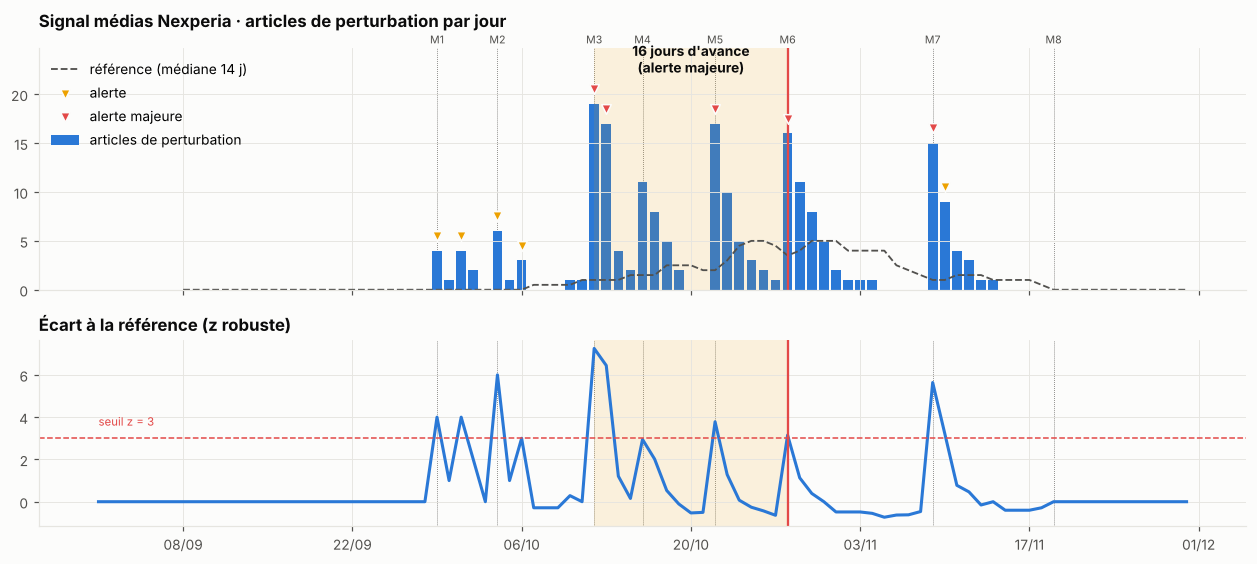

,signal,date,jours d'avance sur l'impact
0,Veille : premier article,2025-09-29,29
1,Alerte : première anomalie,2025-09-29,29
2,Alerte majeure : première anomalie ≥ 10 articles,2025-10-12,16
3,Bascule de type : ≥ 3 articles « pénurie » le même jour,2025-10-16,12


In [11]:
s = (corpus[corpus.nexperia & (corpus.event_type != "aucun")].set_index("published_at").resample("D").size()
     .reindex(pd.date_range(*PERIOD, tz="UTC"), fill_value=0))
past = s.shift(1).rolling(BASELINE_D, min_periods=7)
med = past.median()
mad = s.shift(1).rolling(BASELINE_D, min_periods=7).apply(lambda x: np.median(np.abs(x - np.median(x))), raw=True)
signal = pd.DataFrame({"n": s, "mediane": med, "z": ((s - med) / (1.4826 * mad + 1)).fillna(0)})
hot = signal.z >= Z_ALERT
signal["niveau"] = np.select([hot & (signal.n >= MAJOR_ARTICLES), hot & (signal.n >= MIN_ARTICLES), signal.n >= 1],
                             ["alerte majeure", "alerte", "veille"], "calme")

first_watch = signal.index[signal.niveau != "calme"].min()
first_alert = signal.index[signal.niveau.str.startswith("alerte")].min()
first_major = signal.index[signal.niveau == "alerte majeure"].min()
pen = corpus[corpus.nexperia & (corpus.event_type == "penurie")].set_index("published_at").resample("D").size()
first_shift = pen.index[pen >= MIN_ARTICLES].min()                 # ≥ 3 articles « pénurie » le même jour
lead = pd.DataFrame({
    "signal": ["Veille : premier article", "Alerte : première anomalie", "Alerte majeure : première anomalie ≥ 10 articles",
               "Bascule de type : ≥ 3 articles « pénurie » le même jour"],
    "date": [first_watch, first_alert, first_major, first_shift]})
lead["jours d'avance sur l'impact"] = (IMPACT - lead["date"]).dt.days
lead["date"] = lead["date"].dt.date

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11.5, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
a1.bar(signal.index, signal.n, width=.8, color=C[0], label="articles de perturbation")
a1.plot(signal.index, signal.mediane, color=INK2, lw=1.2, ls="--", label="référence (médiane 14 j)")
for lvl, col in [("alerte", C[3]), ("alerte majeure", C[7])]:
    al = signal[signal.niveau == lvl]
    a1.scatter(al.index, al.n + 1.5, marker="v", s=40, color=col, edgecolors=SURF, linewidths=1, label=lvl, zorder=3)
a2.plot(signal.index, signal.z, color=C[0], label="z robuste")
a2.axhline(Z_ALERT, color=C[7], lw=1, ls="--"); a2.text(signal.index[0], Z_ALERT + .6, f"seuil z = {Z_ALERT:g}", fontsize=7.5, color=C[7])
for a in (a1, a2):
    for _, m in MILESTONES.iterrows(): a.axvline(m.date, color=INK2, lw=.5, ls=":", zorder=0)
    a.axvline(IMPACT, color=C[7], lw=1.5); a.axvspan(first_major, IMPACT, color=C[3], alpha=.12, lw=0)
a1.set_ylim(0, signal.n.max() * 1.3)
a1.text(first_major + (IMPACT - first_major) / 2, signal.n.max() * 1.17, f"{(IMPACT - first_major).days} jours d'avance\n(alerte majeure)",
        ha="center", fontsize=9, fontweight="bold", color=INK)
for _, m in MILESTONES.iterrows(): a1.text(m.date, 1.01, m.id, ha="center", va="bottom", fontsize=7, color=INK2, transform=a1.get_xaxis_transform())
a1.set_title("Signal médias Nexperia · articles de perturbation par jour", pad=14); a1.legend(loc="upper left", ncol=1)
a2.set_title("Écart à la référence (z robuste)"); fmt_dates(a2)
plt.tight_layout(); plt.show()
lead

**Lecture.**
- **Veille et alerte (29/09, 29 jours d'avance)** : la référence est nulle, donc trois articles suffisent à déclencher une anomalie. Pour un fournisseur habituellement absent de la presse, la **nouveauté** est le signal. À ce stade, l'action attendue est une mise sous surveillance.
- **Alerte majeure (12/10, 16 jours d'avance)** : l'annonce néerlandaise est la première journée à 10 articles ou plus. C'est la marge utile pour activer un stock de sécurité ou un second fournisseur.
- **Bascule de type (16/10, 12 jours)** : moins précoce, mais elle qualifie l'impact industriel. Combiner volume et type permet de filtrer les pics purement politiques.
- Après l'impact, le z-score retombe malgré un volume encore élevé, parce que la référence s'adapte. Une alerte ouverte doit donc rester active jusqu'à une désescalade explicite, et ne pas s'éteindre d'elle-même.

En mode replay, chaque jour est évalué uniquement avec les articles publiés jusqu'à ce jour : aucune alerte n'est calculée a posteriori.

In [12]:
def as_of(date):
    d = pd.Timestamp(date, tz="UTC") + pd.Timedelta(days=1)
    seen = corpus[(corpus.published_at < d) & corpus.nexperia & (corpus.event_type != "aucun")]
    sig = signal.loc[:pd.Timestamp(date, tz="UTC")]
    return {"jour J": date, "articles vus": len(seen), "groupes": seen["cluster_id"].nunique(),
            "types": ", ".join(seen["event_type"].value_counts().index[:2]) or "-",
            "entreprises touchées": ", ".join(sorted({COMPANIES[c][0] for l in seen["companies"] for c in l} - {"Nexperia", "Wingtech"})) or "-",
            "niveau (7 derniers jours)": next((l for l in ["alerte majeure", "alerte", "veille"] if (sig.niveau.tail(7) == l).any()),
                                      "veille" if (sig.niveau != "calme").any() else "calme")}
pd.DataFrame([as_of(d) for d in ["2025-09-25", "2025-10-01", "2025-10-08", "2025-10-13", "2025-10-20", "2025-10-27"]])

,jour J,articles vus,groupes,types,entreprises touchées,niveau (7 derniers jours)
0,2025-09-25,0,0,-,-,calme
1,2025-10-01,9,3,sanction,-,alerte
2,2025-10-08,21,6,sanction,-,alerte
3,2025-10-13,59,12,sanction,-,alerte majeure
4,2025-10-20,91,16,"sanction, penurie","Bosch, Valeo, ZF",veille
5,2025-10-27,129,23,"sanction, penurie","Bosch, Valeo, Volkswagen, ZF",alerte majeure


**Lecture « jour J ».** Le 27/10, veille de l'arrêt, l'outil sait que la crise est passée du réglementaire à la pénurie et qu'elle touche des rangs 1 (Bosch, ZF, Valeo) puis un constructeur (Volkswagen). Il ne cite pas encore Honda. La propagation jusqu'aux sites dépendants de Nexperia appartient au Bloc 4, à partir du graphe fournisseurs. Le 20/10, le niveau retombe à « veille » alors que la crise s'aggrave : c'est la limite décrite plus haut (alerte non persistante).

La colonne niveau donne le niveau le plus élevé atteint sur les 7 derniers jours.

## 6. Sortie vers le Bloc 4 · format commun des agents

In [13]:
def build_event(cid, g):
    g = g.sort_values("published_at")
    places = [p for l in g["places"] for p in l]
    loc = max(sorted(set(places)), key=lambda p: (PLACES[p][4], places.count(p))) if places else None
    ents, seen = [], set()
    for c in [c for l in g["companies"] for c in l]:
        if c not in seen: seen.add(c); ents.append({"id": f"SUP:{c}", "name": COMPANIES[c][0], "role": "touché"})
    missing = ["weather", "finance"] + (["location"] if loc is None else []) + (["entities"] if not ents else ["entities.lei"])
    return {"event": {"id": cid, "type": g["event_type"].mode().iat[0], "label": g.iloc[0]["title"]},
            "date": g["published_at"].min().date().isoformat(),
            "location": {"name": loc, "lat": PLACES[loc][1] if loc else None, "lon": PLACES[loc][2] if loc else None},
            "entities": ents,
            "media": [{"titre": r.title, "date": r.published_at.strftime("%Y-%m-%dT%H:%M:%SZ"), "source_id": r.source_id} for r in g.itertuples()],
            "donnees_manquantes": missing}

risk = corpus[corpus.nexperia & (corpus.event_type != "aucun")]
events = [build_event(cid, g) for cid, g in risk.groupby("cluster_id")]
events = [e for e in events if e["event"]["type"] != "aucun"]
assert all(list(e) == ["event", "date", "location", "entities", "media", "donnees_manquantes"] and e["media"] for e in events)
assert {m["source_id"] for e in events for m in e["media"]} <= set(corpus["source_id"])     # aucun fait sans source

stamp = "synth" if SYNTH else "replay"
(OUT / f"events_media_nexperia_{stamp}.json").write_text(json.dumps(events, ensure_ascii=False, indent=1), encoding="utf-8")
signal.assign(date=signal.index.date).to_csv(OUT / f"signal_media_nexperia_{stamp}.csv", index=False)
print(f"{len(events)} événements exportés · {sum(len(e['media']) for e in events)} sources · fichiers dans {OUT}/")
pd.DataFrame([{"id": e["event"]["id"], "date": e["date"], "type": e["event"]["type"], "lieu": e["location"]["name"],
               "entités": ", ".join(x["name"] for x in e["entities"]), "sources": len(e["media"]), "label": e["event"]["label"]}
              for e in sorted(events, key=lambda e: -len(e["media"]))[:8]])

28 événements exportés · 207 sources · fichiers dans data/processed/


,id,date,type,lieu,entités,sources,label
0,evt_0129,2025-10-28,penurie,Celaya,"Nexperia, Honda",23,Nexperia chip shortage forces Honda to cut output in Mexico
1,evt_0130,2025-10-28,penurie,Celaya,"Nexperia, Honda",21,Honda suspend la production de son usine mexicaine faute de puces
2,evt_0157,2025-11-09,sanction,Beijing,Nexperia,17,La Chine assouplit l'interdiction d'exportation des puces Nexperia
3,evt_0085,2025-10-12,sanction,The Hague,"Nexperia, Wingtech",16,Netherlands takes over Chinese-owned Nexperia citing supply risks
4,evt_0158,2025-11-09,sanction,Beijing,Nexperia,16,China grants exemptions to Nexperia export ban
5,evt_0089,2025-10-12,sanction,The Hague,"Nexperia, Wingtech",15,Dutch government takes control of chipmaker Nexperia under Cold War-era law
6,evt_0088,2025-10-12,sanction,Nijmegen,"Nexperia, Wingtech",12,Les Pays-Bas placent sous tutelle Nexperia
7,evt_0114,2025-10-22,penurie,Wolfsburg,"Volkswagen, Nexperia",11,Volkswagen warns of production stoppage as Nexperia chip shortage bites


In [14]:
print(json.dumps(max(events, key=lambda e: len(e["media"])) | {"media": "…"}, ensure_ascii=False, indent=1)[:900])

{
 "event": {
  "id": "evt_0129",
  "type": "penurie",
  "label": "Nexperia chip shortage forces Honda to cut output in Mexico"
 },
 "date": "2025-10-28",
 "location": {
  "name": "Celaya",
  "lat": 20.523,
  "lon": -100.815
 },
 "entities": [
  {
   "id": "SUP:S001",
   "name": "Nexperia",
   "role": "touché"
  },
  {
   "id": "SUP:C001",
   "name": "Honda",
   "role": "touché"
  }
 ],
 "media": "…",
 "donnees_manquantes": [
  "weather",
  "finance",
  "entities.lei"
 ]
}


## 7. Synthèse

In [15]:
kpi = {"Articles analysés": len(corpus), "Articles Nexperia": int(corpus.nexperia.sum()), "Langues": corpus.language.nunique(),
       "Groupes d'événements (tous sujets)": n_evt, "Événements Nexperia exportés": len(events)}
if SYNTH:
    kpi |= {"ARI déduplication": round(adjusted_rand_score(corpus.true_event, corpus.cluster_id), 3),
            "F1 macro classification (hybride)": scores.loc["Hybride (retenu)", "F1 macro"]}
kpi |= {"Jours d'avance · veille": int((IMPACT - first_watch).days), "Jours d'avance · alerte": int((IMPACT - first_alert).days),
        "Jours d'avance · alerte majeure": int((IMPACT - first_major).days),
        "Jours d'avance · bascule « pénurie »": int((IMPACT - first_shift).days)}
pd.Series(kpi, name="valeur", dtype=object).to_frame()

,valeur
Articles analysés,1225
Articles Nexperia,305
Langues,4
Groupes d'événements (tous sujets),199
Événements Nexperia exportés,28
ARI déduplication,0.333
F1 macro classification (hybride),0.957
Jours d'avance · veille,29
Jours d'avance · alerte,29
Jours d'avance · alerte majeure,16


**Conclusion.** Sur le cas Nexperia, le volet médias émet une **alerte majeure 16 jours avant** l'arrêt de production chez Honda, et un **signal de veille 29 jours avant**. Chaque alerte est datée et rattachée à ses `source_id`. La valeur ajoutée vient de la combinaison de trois signaux : **volume anormal + bascule de type + extension aux rangs aval**. Un seul ne suffit pas.

| Limite | Effet | Piste |
|---|---|---|
| Corpus synthétique | les scores valident la chaîne, pas la performance | replay GKG réel (`collect_replay`) + échantillon annoté |
| Déduplication sur titres | fusions et éclatements (ARI ≈ 0,33) | embeddings multilingues + texte complet |
| Mots-clés monolingues | une partie de M3 (FR, DE, NL) et tout M8 sont manqués | zero-shot NLI multilingue |
| Pas de polarité ni de persistance | la levée (M7) ressemble à l'escalade ; l'alerte retombe en pleine crise | champ `polarite`, alerte close seulement sur désescalade |
| Une seule crise | l'avance mesurée est un cas, pas une moyenne | backtesting Helene, grève des ports, terres rares |

**Fichiers produits** : `events_media_nexperia_*.json` (format commun, entrée du Bloc 4) et `signal_media_nexperia_*.csv` (série quotidienne et niveau d'alerte).